#Module 7 Lab 4

##Part 1: Setup

###Import Packages

In [142]:
#import necessary packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

##Part 2: Load the Dataset

###Load ramen-ratings.csv

In [143]:
#import ramen-ratings.csv
df = pd.read_csv('ramen-ratings.csv')
#display first 5 rows
df.head()

,Brand,Variety,Style,Country,Stars
0,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75
1,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00
2,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25
3,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75
4,Ching's Secret,Singapore Curry,Pack,India,3.75


##Part 3: Explore the *Data*

###Run Info and Summary Cells

In [145]:
#get shape, datatypes, sample and missing values
df.info()

df.describe()

sample_row = df.sample()
display(sample_row)

missing_values = df.isnull().sum()
display(missing_values)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2577 entries, 0 to 2576
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Brand    2577 non-null   object 
 1   Variety  2577 non-null   object 
 2   Style    2575 non-null   object 
 3   Country  2577 non-null   object 
 4   Stars    2577 non-null   float64
dtypes: float64(1), object(4)
memory usage: 100.8+ KB


,Brand,Variety,Style,Country,Stars
1663,Nissin,Ramen Shop Sapporo Miso,Pack,Japan,4.0


,0
Brand,0
Variety,0
Style,2
Country,0
Stars,0


In [146]:
#drop no values in Style feature
df = df.dropna(subset=['Style'])

#verify missing values were removed
missing_values = df.isnull().sum()
display(missing_values)


,0
Brand,0
Variety,0
Style,0
Country,0
Stars,0


In [147]:
#get unique values for each feature
print("Number of Unique Values in Each Feature:")
print(df.nunique())
display(df.nunique())

Number of Unique Values in Each Feature:
Brand       355
Variety    2408
Style         7
Country      38
Stars        42
dtype: int64


,0
Brand,355
Variety,2408
Style,7
Country,38
Stars,42


In [148]:
#display all types of styles along with counts within each style
style_counts = df['Style'].value_counts()
print("Style Counts:")
print(style_counts)

Style Counts:
Style
Pack    1528
Bowl     481
Cup      450
Tray     108
Box        6
Can        1
Bar        1
Name: count, dtype: int64


In [149]:
#obtain summary statistics
print("Summary Statistics for Features:")
display(df.describe())

print("\nSummary Statistics for Categorical Features:")
display(df.describe(include='object'))

Summary Statistics for Features:


,Stars
count,2575.000000
mean,3.654893
std,1.015641
min,0.000000
25%,3.250000
50%,3.750000
75%,4.250000
max,5.000000



Summary Statistics for Categorical Features:


,Brand,Variety,Style,Country
count,2575,2575,2575,2575
unique,355,2408,7,38
top,Nissin,Chicken,Pack,Japan
freq,381,7,1528,352


In [150]:
#obtain country list to verify redundancies
df['Country'].unique().tolist()

['Japan',
 'Taiwan',
 'USA',
 'India',
 'South Korea',
 'Singapore',
 'Thailand',
 'Hong Kong',
 'Vietnam',
 'Ghana',
 'Malaysia',
 'Indonesia',
 'China',
 'Nigeria',
 'Germany',
 'Hungary',
 'Mexico',
 'Fiji',
 'Australia',
 'Pakistan',
 'Bangladesh',
 'Canada',
 'Nepal',
 'Brazil',
 'UK',
 'Myanmar',
 'Netherlands',
 'United States',
 'Cambodia',
 'Finland',
 'Sarawak',
 'Philippines',
 'Sweden',
 'Colombia',
 'Estonia',
 'Holland',
 'Poland',
 'Dubai']

###Noticed the lables USA and United States in the Country column that will skew analytics going forward as results may split or partition reviews from the same Country

In [151]:
#Combined separate Country lables "USA" and "United States"
df['Country'] = df['Country'].replace('USA', 'United States')

df['Country'].unique().tolist()

['Japan',
 'Taiwan',
 'United States',
 'India',
 'South Korea',
 'Singapore',
 'Thailand',
 'Hong Kong',
 'Vietnam',
 'Ghana',
 'Malaysia',
 'Indonesia',
 'China',
 'Nigeria',
 'Germany',
 'Hungary',
 'Mexico',
 'Fiji',
 'Australia',
 'Pakistan',
 'Bangladesh',
 'Canada',
 'Nepal',
 'Brazil',
 'UK',
 'Myanmar',
 'Netherlands',
 'Cambodia',
 'Finland',
 'Sarawak',
 'Philippines',
 'Sweden',
 'Colombia',
 'Estonia',
 'Holland',
 'Poland',
 'Dubai']

###Combined Country lables "USA" and "United States" for more accurate analysis

###Dataset Description: The dataset containing multiple brands and varieties of ramen noodles. The dataset consists of 2,577 instances containing five features in object type such as the brand, type of variety or flavors included, the style of how the ramen are packaged from pack to bowl, the country of origin and lastly a float reflecting the ratings of the ramen measured in a numerical star range from 0-5.

##Part 4: Visualization Analysis

###Distribution Analysis

###Category 1:

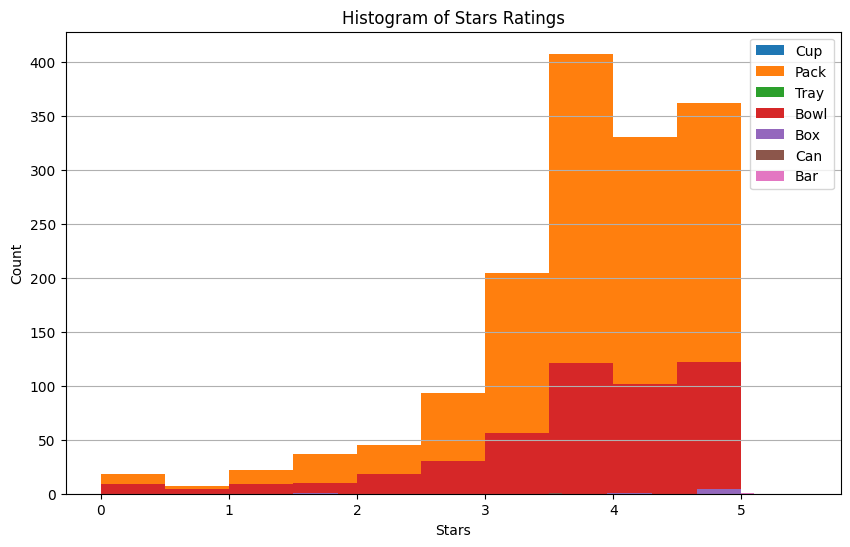

In [152]:
#create histogram of star ratings with legend for each style type
plt.figure(figsize=(10, 6))
for style in df['Style'].unique():
    subset = df[df['Style'] == style]
    subset['Stars'].plot(kind='hist', label=style)
plt.title('Histogram of Stars Ratings')
plt.xlabel('Stars')
plt.ylabel('Count')
plt.grid(axis='y', alpha=1)
plt.legend()
plt.show()

#The histogram above shows the distribution of stars across the style types using color variations to measure the density of the counts across the style variations for comparison. This shows that the pack and bowl styles are the most predominant styles that were rated.

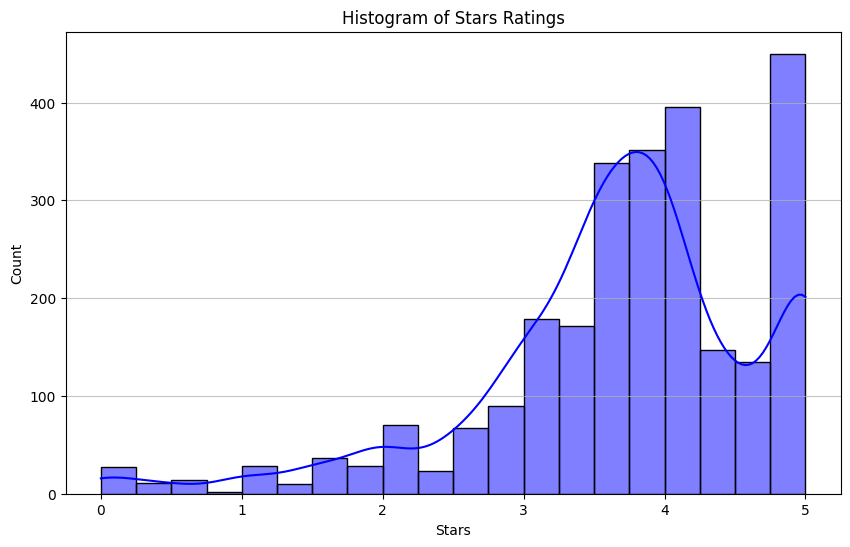

In [153]:
#Histogram of Star Ratings
plt.figure(figsize=(10, 6))
sns.histplot(df['Stars'], bins=20, kde=True, color='blue')
plt.title('Histogram of Stars Ratings')
plt.xlabel('Stars')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.show()

###The histogram above shows the distribution of the stars from the rating of 0 through the maximum of 5.  The chart shows a majority of the overall count to be rated above 3 starts when looked at the entire distribution of instances across the rating band.

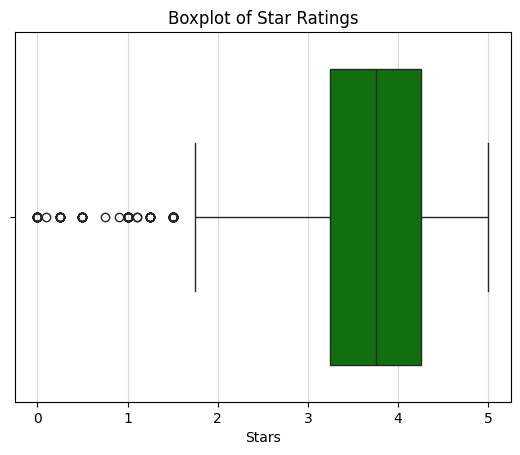

In [154]:
#boxplot of star ratings
sns.boxplot(data=df, x='Stars', color='green')
plt.title('Boxplot of Star Ratings')
plt.xlabel('Stars')
plt.grid(axis='x', alpha=0.5)
plt.show()
#

###This boxplot reflects the distribution of stars by minium and maximum value ranges along with reflecting where the outliers lie in the ratings band. Those outliers show to reside predominantly in the 1.5 star range and below.

###Category 2:

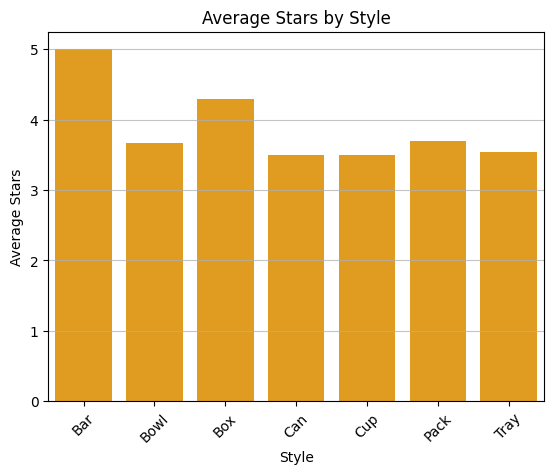

In [155]:
#create barplot to show average stars by styles
style_average = df.groupby('Style')['Stars'].mean()
sns.barplot(x=style_average.index, y=style_average.values, color='orange')
plt.title('Average Stars by Style')
plt.xlabel('Style')
plt.ylabel('Average Stars')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.show()


###The above shows a box plot of average stars in each of the styles contained in the dataset. Important note is that the bar and the can styles have one single value instance each within the dataset which should be taken into account when comparing those two styles against the others.

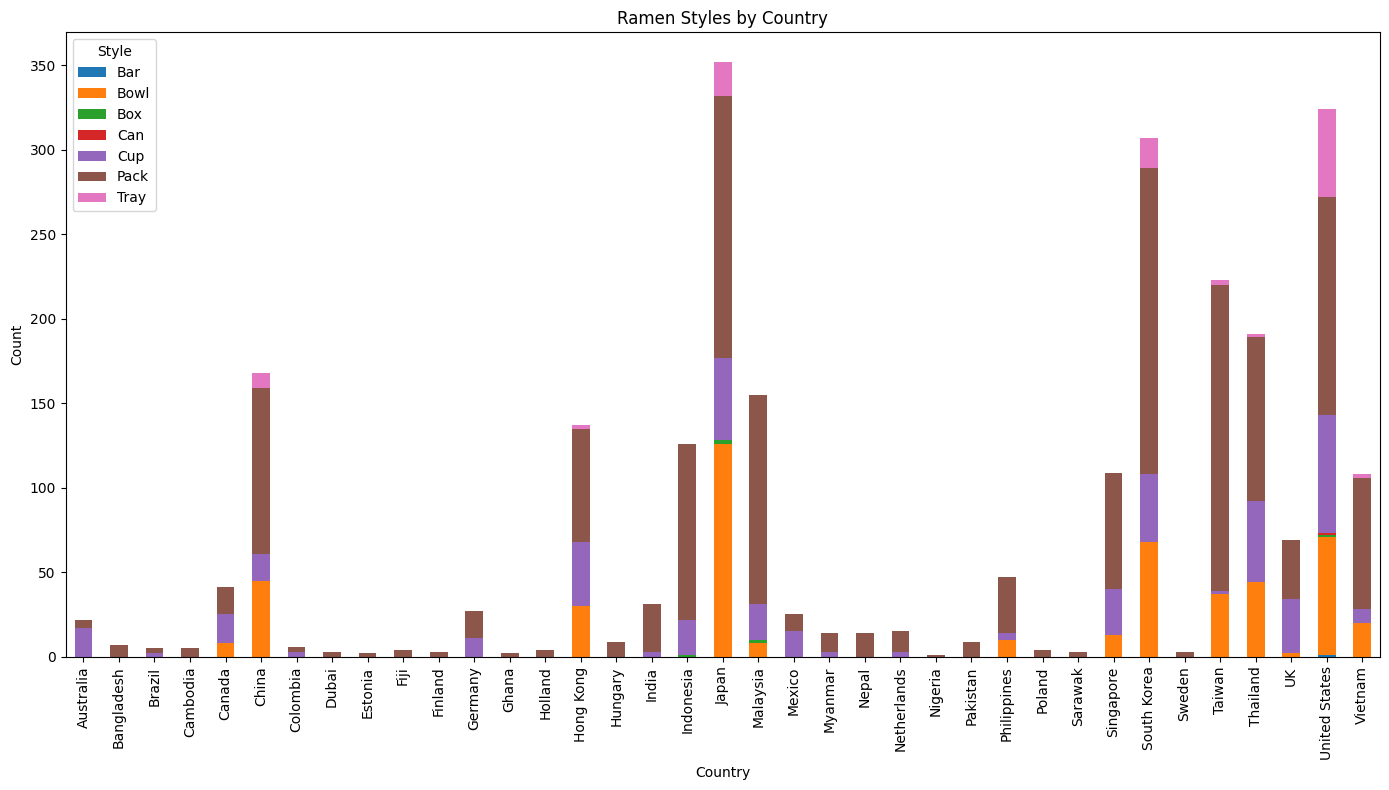

In [156]:
#create stacked bar chart to show ramen styles by country
country_style_dist = df.groupby(['Country', 'Style']).size().unstack(fill_value=0)
country_style_dist.plot(kind='bar', stacked=True, figsize=(14, 8))
plt.title('Ramen Styles by Country')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.legend(title='Style')
plt.tight_layout()
plt.show()

###The stacked bar chart above showcases the style distribution across the countries within the dataset. This shows that the USA uses the highest concentration of tray styles where Australia shows to overwhelmingly use the cup method.

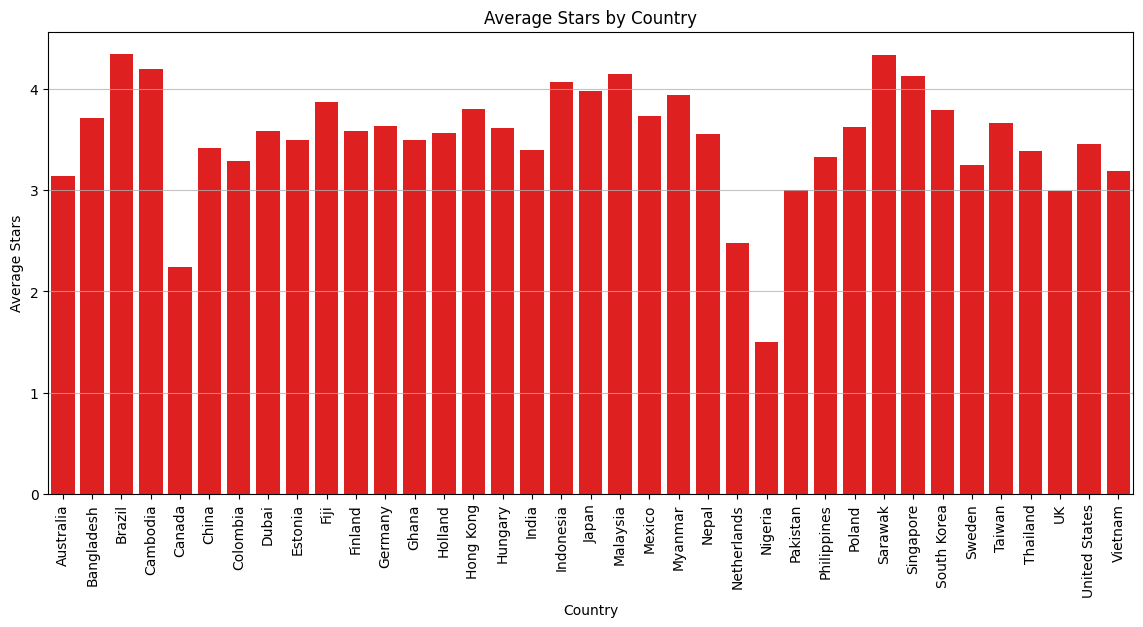

In [157]:
#group by country to get the average stars by country
country_average = df.groupby('Country')['Stars'].mean()

#filter country avearge to only include averages 2 and above
country_average_filtered = country_average[country_average >= 2]

#create barplot to show average stars by country with only including countries
#with only 2 or more stars each
plt.figure(figsize=(14, 6))
sns.barplot(x=country_average.index, y=country_average.values, color='red')
plt.title('Average Stars by Country')
plt.xlabel('Country')
plt.ylabel('Average Stars')
plt.xticks(rotation=90)
plt.grid(axis='y', alpha=0.75)
plt.tight_layout
plt.show()

###The above barplot showcases the average stars by country that have at least a 2 star or above rating. Canada stands out as a country with an abnormally low average stars amongts their peer countries.

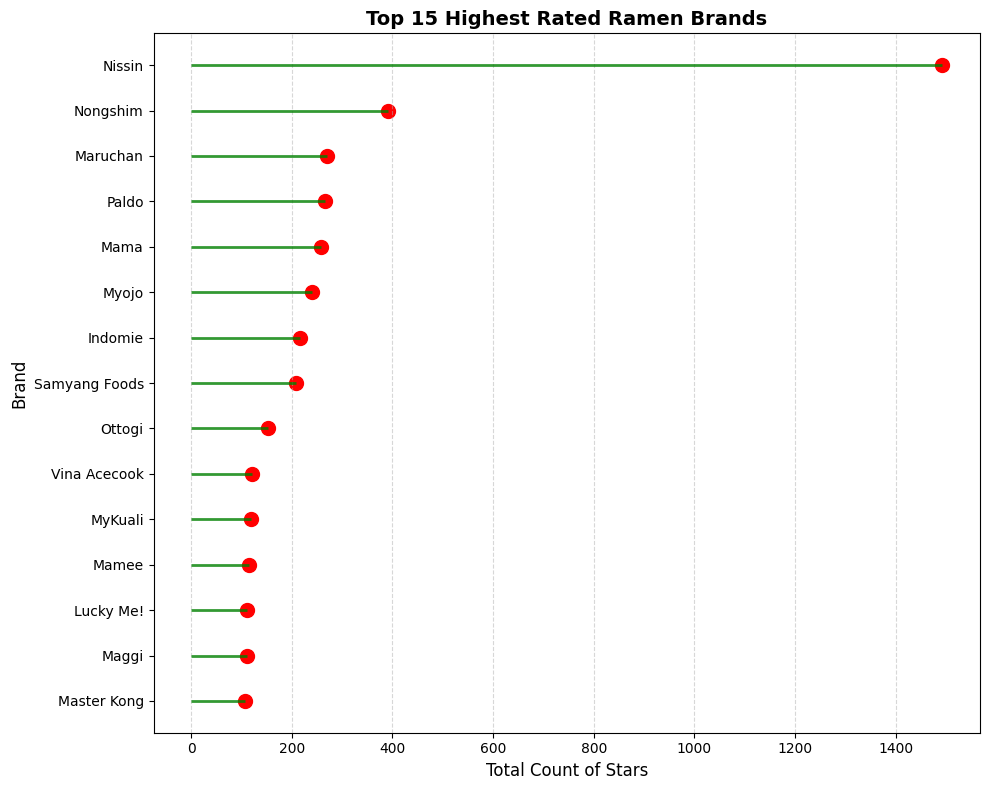

In [158]:
#group brands by sum of stars to determine highest 15 scored brands
top_brands = df.groupby('Brand')['Stars'].sum().sort_values(ascending=False).head(15)

#sorted values so the highest value starts on top of the chart
top_brands = top_brands.sort_values(ascending=True)

#create lollipop chart
plt.figure(figsize=(10, 8))
plt.hlines(y=top_brands.index, xmin=0, xmax=top_brands.values, color='green', alpha=0.8, linewidth=2)
plt.scatter(x=top_brands.values, y=top_brands.index, color='red', alpha=1, s=100)
plt.title('Top 15 Highest Rated Ramen Brands', fontsize=14, fontweight='bold')
plt.xlabel('Total Count of Stars', fontsize=12)
plt.ylabel('Brand', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

###The above lollipop chart shows the top 15 brands taken from a sum of all star reviews. Then sorted to show the highest being Nissin, which has close to three times the total star rankings than then 2nd place brand on the list.

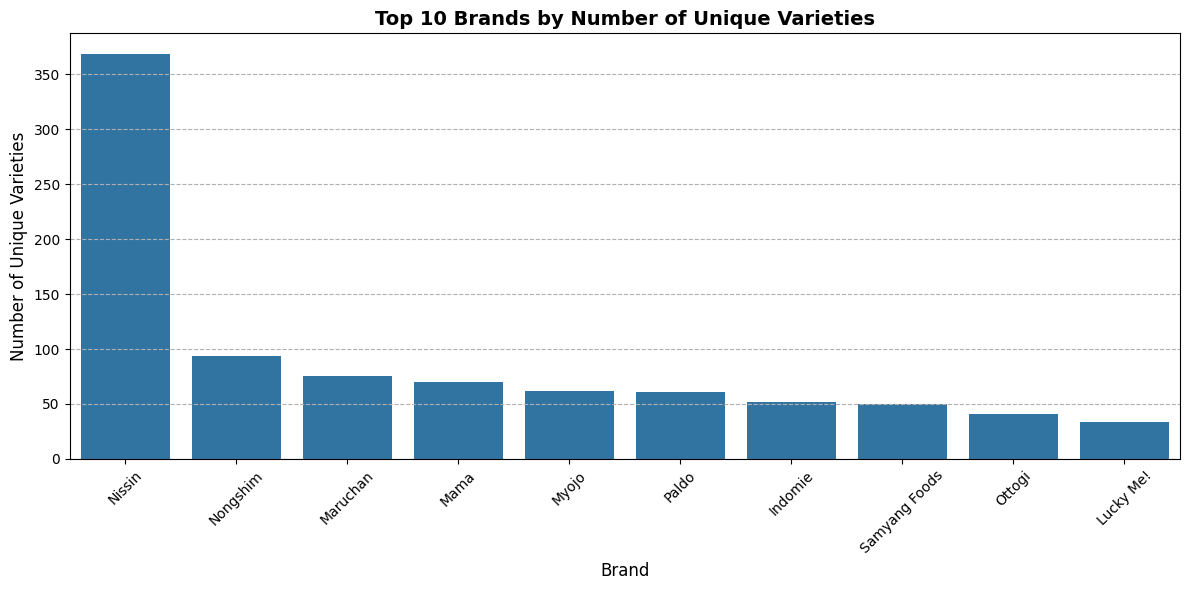

In [159]:
#find top 10 brands by variety
top_brands_variety = df.groupby('Brand')['Variety'].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_brands_variety.index, y=top_brands_variety.values, legend=True)
plt.title('Top 10 Brands by Number of Unique Varieties', fontsize=14, fontweight='bold')
plt.xlabel('Brand', fontsize=12)
plt.ylabel('Number of Unique Varieties', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()


###The above bar chart reflects the brands that have the 10 highest number of varieties. The Nissin brand has by far the most diverse amount of varieties in its brand catalog with more than 3 times the variety choices compared to the second highest Nongshim.

##Category 3

###Relationship and Trend Analysis

In [160]:
#imported numpy to aid in randomizing years to all instances in dataset for futher
import numpy as np
years_pool = np.arange(2000, 2021)
np.random.seed(20)
df['Year'] = np.random.choice(years_pool, size=len(df))
df.head()

#assure year randomizer are listed as whole numbers not floats
df['Year'] = df['Year'].astype(int)
df.head()

,Brand,Variety,Style,Country,Stars,Year
0,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,2003
1,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00,2015
2,Nissin,Cup Noodles Chicken Vegetable,Cup,United States,2.25,2009
3,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,2020
4,Ching's Secret,Singapore Curry,Pack,India,3.75,2011


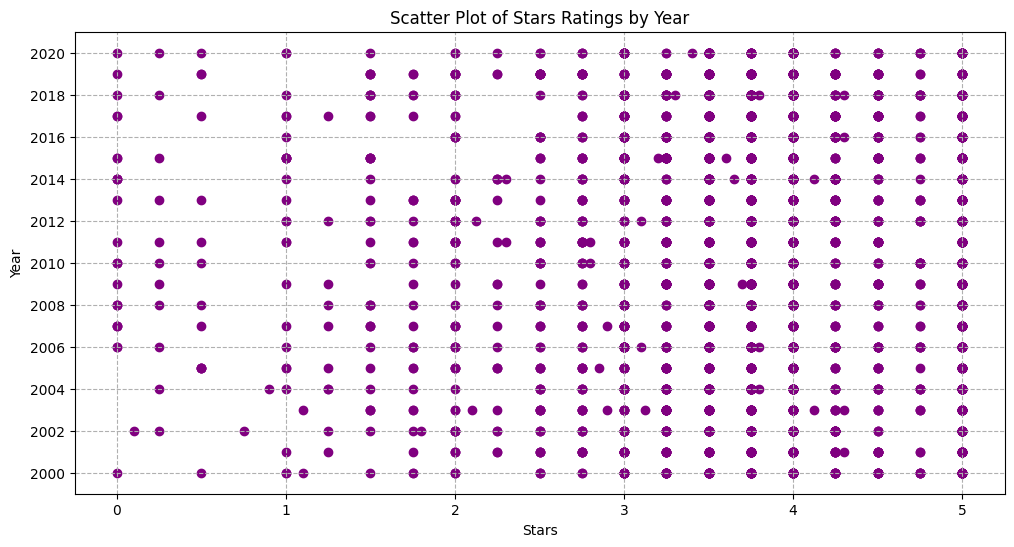

In [161]:
#create scatter plot to show stars ratings by year and include ticks for every two years
plt.figure(figsize=(12, 6))
plt.scatter(data=df, x='Stars', y='Year', color='purple')
plt.title('Scatter Plot of Stars Ratings by Year')
plt.xlabel('Stars')
plt.ylabel('Year')
plt.yticks(np.arange(2000, 2021, 2))
plt.grid(True, linestyle='--')
plt.show()

###The above is a scatterplot reflecting the distrubution of stars by years 2000-2020. The Year 2012 and 2016 both show to have no reviews 1 stars or below.

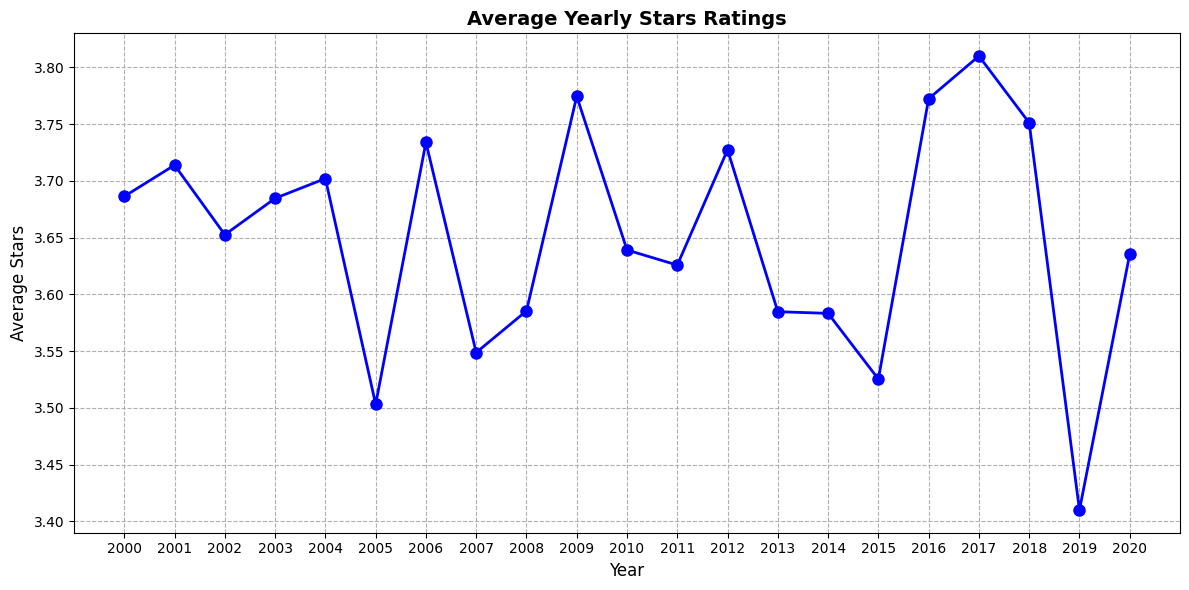

In [162]:
#find average stars by year
yearly_average = df.groupby('Year')['Stars'].mean()

#create line plot to map out average stars from the years 2000-2020
#to show fluctionats from year to year
plt.figure(figsize=(12,6))
plt.plot(yearly_average.index, yearly_average.values, color='blue', marker='o', linewidth=2, markersize=8)
plt.title('Average Yearly Stars Ratings', fontsize='14', fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Stars', fontsize=12)
plt.xticks(np.arange(2000, 2021, 1))
plt.grid(True, linestyle='--')
plt.tight_layout()
plt.show()

###The lineplot above measures the average yearly star ratings over the course of 20 years starting in 2000 through 2020. The lowest average rating was seen in 2003 with the highest in 2008. Also noted was the years of 2016 thru 2020 that shown a minimumal year to year fluctuations throughout the entire timeframe compared to the trend of previous years.

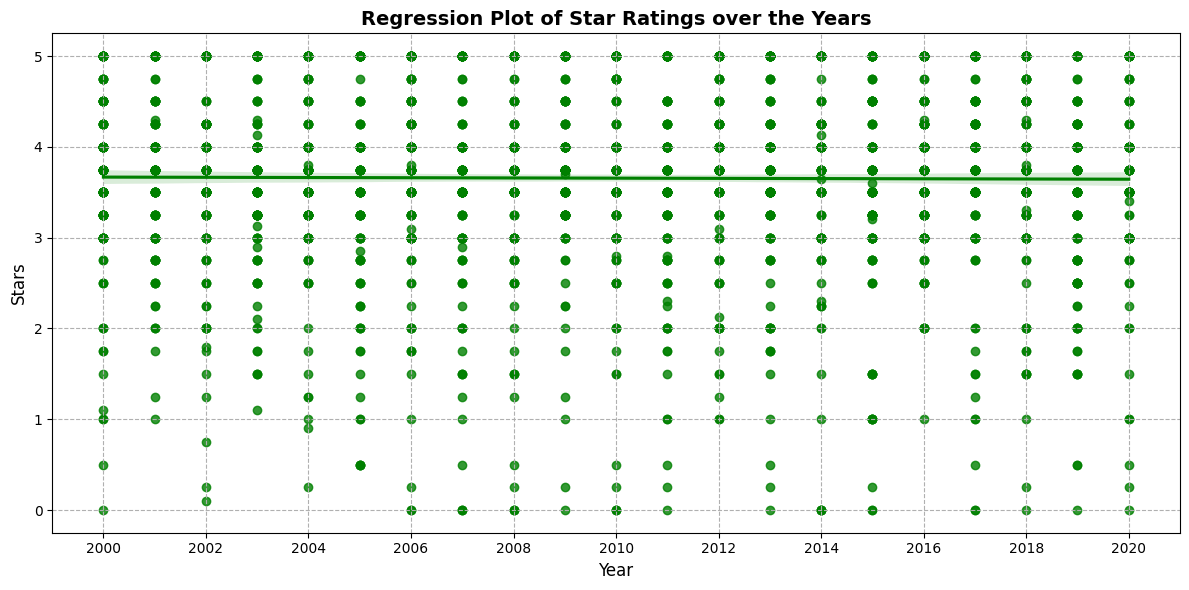

In [163]:
#create regression plot for star ratings over the years 2000-2020
plt.figure(figsize=(12, 6))
sns.regplot(data=df, x='Year', y='Stars', color='green')
plt.title('Regression Plot of Star Ratings over the Years', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Stars', fontsize=12)
plt.xticks(np.arange(2000, 2021, 2))
plt.grid(True, linestyle='--')
plt.tight_layout()
plt.show()

###The above chart shows a regression line pertaining to the star ratings over the years. The fact that the regression line stays consistent throughout the years is due to the years being randomly generated at the beginning of Category 3 leading to the statistical result of having no variances seen throughout the timeline.

##Reflection:

###Which chart helped you the most and why? The stacked bar chart helped the most as it produced multiple levels of data insights from total count of styles contained within each country, but it also allowed for the ability to easily see which styles were being reviwed within each country as well. It also allowed us to see what styles are available within each country but it allowed us to measure of the diversity (or lack thereof) of product styles within each country as well.

###Did anything surprise you in the data? Yes, the yearly avearges of 0-5 star ratings only fluctuated under 0.50 when placed into a time-frame simulation. Meaning that without the time-frame simulation, the average star ratings only fluctuated 10% within the total star rating range throughout the dataset.

###How did visualization help compared to just looking at raw rows? It helped see trends extremly quickly especially when comparing country to country. This would allow stakeholders the ability to see market gaps in styles by country, along with the density of varieties bieng offered that favor one company inparticular. The data visualizations would help companies at the bottom of the market share list increase thier market share in those markets by possibly introducting additional varietiest and styles to help close the gap that more established companies hold on those territories.